Learned Word Embeddings (E):
computer       : [-0.07153809  0.16444883  0.32881675  0.14032006  0.83406925]...
in             : [-0.01911786 -0.06649822  0.02261064  0.06837113 -0.01763195]...
useful         : [ 0.03993779  0.02794606  0.08172535 -0.00695885  0.21124291]...
ok             : [-0.19397391 -0.02607937  0.03047354  0.10887432  0.32387302]...
may            : [-0.04719706 -0.01255972  0.15803075  0.04597919  0.00526895]...
a              : [-0.263101   -0.07246639  0.57584262 -0.25823421 -0.44200228]...
boy            : [ 0.05048969  0.0229732   0.02210706  0.12671076 -0.11525967]...
male           : [ 0.24932104  0.05029921  0.11211013 -0.01318731 -0.4251423 ]...
was            : [-0.29375147 -0.03889231  0.07800919  0.15171072  0.28877058]...
the            : [ 0.37839999 -0.00915959  0.16968836  0.05480738 -0.0212207 ]...
science        : [ 0.2812868   0.72166073 -0.23457291  0.37215299  0.20470734]...
do             : [-0.16309873  0.06250299  0.08988929  0.1557912   0.

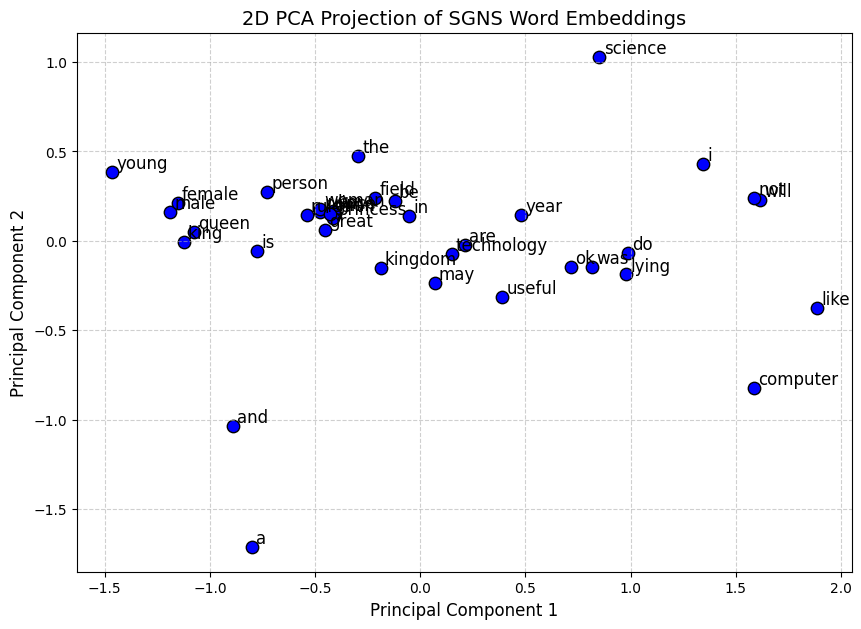

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# 1. Corpus Definition
corpus = [
    # Gender / Royalty pairs
    "king is male and rules the kingdom",
    "queen is female and rules the kingdom",
    "man is a male person",
    "woman is a female person",
    "boy is a young male",
    "girl is a young female",
    "prince is a young king and male",
    "princess is a young queen and female",
    # Computer / Science / Tech context
    "i do not like computer science",
    "ok i will like computer science",
    "may be in a year i will like computer science",
    "i was lying i will not like computer science",
    "computer science is a great field",
    "technology and science are useful",
]

# Hyperparameters
c = 2          # Window size
d = 50         # Embedding dimension
eta = 0.01     # Learning rate
T = 100        # Epochs
k_neg = 5      # Number of negative samples per positive pair

# --- 1. Build Vocabulary V and Sampling Distribution ---
words = [word.lower() for doc in corpus for word in doc.split()]
vocab = list(set(words))
vocab_size = len(vocab)
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for i, w in enumerate(vocab)}

# Calculate word counts for 3/4 unigram noise distribution
word_counts = np.zeros(vocab_size)
for w in words:
    word_counts[word2idx[w]] += 1

unigram_dist = word_counts ** 0.75
unigram_dist /= np.sum(unigram_dist)

# --- 2 & 3. Initialize Embeddings E (Center) and W (Context) ---
np.random.seed(42)
E = np.random.randn(vocab_size, d) * 0.01  # Center word vectors (V, d)
W = np.random.randn(vocab_size, d) * 0.01  # Context word vectors (V, d)

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -6, 6)))

# --- 5. Training Loop (Skip-Gram with Negative Sampling) ---
for epoch in range(T):
    # --- 4. Generate Training Pairs ---
    pairs = []
    for sentence in corpus:
        tokens = sentence.lower().split()
        for i, word in enumerate(tokens):
            center_idx = word2idx[word]
            for j in range(max(0, i - c), min(len(tokens), i + c + 1)):
                if i != j:
                    context_idx = word2idx[tokens[j]]
                    pairs.append((center_idx, context_idx))

    # Shuffle training pairs
    np.random.shuffle(pairs)

    total_loss = 0.0

    for center, context in pairs:
        v_c = E[center]        # Center word vector (d,)
        u_o = W[context]       # Positive context word vector (d,)

        # Sample k negative context words
        neg_indices = np.random.choice(vocab_size, size=k_neg, p=unigram_dist)

        # Forward pass - Positive Target
        score_pos = np.dot(u_o, v_c)
        sig_pos = sigmoid(score_pos)

        # Loss: -log(sigmoid(score_pos))
        loss = -np.log(sig_pos + 1e-9)

        # Gradients initialization for center vector v_c
        grad_v_c = np.zeros(d)

        # Gradient w.r.t positive context word: (sigmoid(score_pos) - 1) * v_c
        grad_u_o = (sig_pos - 1.0) * v_c
        grad_v_c += (sig_pos - 1.0) * u_o

        # Update positive context vector W[context]
        W[context] -= eta * grad_u_o

        # Forward & Backward pass - Negative Samples
        for neg_idx in neg_indices:
            u_n = W[neg_idx]
            score_neg = np.dot(u_n, v_c)
            sig_neg = sigmoid(score_neg)

            # Loss contribution: -log(sigmoid(-score_neg))
            loss += -np.log(sigmoid(-score_neg) + 1e-9)

            # Gradient w.r.t negative context word: sigmoid(score_neg) * v_c
            grad_u_n = sig_neg * v_c
            grad_v_c += sig_neg * u_n

            # Update negative context vector W[neg_idx]
            W[neg_idx] -= eta * grad_u_n

        # Update center word vector E[center]
        E[center] -= eta * grad_v_c
        total_loss += loss

print("Learned Word Embeddings (E):")
for word in vocab:
    print(f"{word:15s}: {E[word2idx[word]][:5]}...")  # Showing first 5 dimensions

# --- PCA Projection & Visualization ---
words_list = list(vocab)
matrix_E = np.array([E[word2idx[w]] for w in words_list])

pca = PCA(n_components=2)
coords_2d = pca.fit_transform(matrix_E)

plt.figure(figsize=(10, 7))
plt.scatter(coords_2d[:, 0], coords_2d[:, 1], color="blue", edgecolors="k", s=80)

for i, word in enumerate(words_list):
    plt.annotate(
        word, (coords_2d[i, 0] + 0.02, coords_2d[i, 1] + 0.02), fontsize=12
    )

plt.title("2D PCA Projection of SGNS Word Embeddings", fontsize=14)
plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()